In [1]:
import yfinance as yf
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

import warnings

warnings.simplefilter(action='ignore', category=FutureWarning)

# Research Question
Are changes in the interest rates associated with XU100 returns? If so, does this relationship differ between TL-denominated and USD-denominated returns?

### Two Different Sub-questions

**Contemporaneous relationship:** How do XU100 returns behave in months when interest rates change?

**Prediction:** Does this month's change in interest rates help predict next month's XU100 returns?

We use monthly data because the policy rate changes only a few times a year; at daily frequency, the rate-change variable would be zero on almost every observation. Monthly frequency aligns the data with the pace of rate decisions and gives roughly 180 observations over 15 years. This is a relatively small sample, so the statistical power of our tests will be limited and results should be interpreted with caution.

In [2]:
r = pd.read_excel("EVDS_25-10-2026.xlsx")

e:\Anaconda\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [3]:
r = r[["Tarih","TP_APIFON4"]]
r = r.iloc[:-9]



In [4]:
r = r.sort_index(ascending=False)


In [5]:
r = r.set_index(r["Tarih"])
r = r["TP_APIFON4"]
r


Tarih
2011-01     6.25
2011-02     6.25
2011-03     6.25
2011-04     6.25
2011-05     6.25
           ...  
2026-06       40
2026-07       40
2026-08       37
2026-09       37
2026-10    36.04
Name: TP_APIFON4, Length: 190, dtype: object

In [6]:
xu100 = yf.download("XU100.IS", start="2011-01-01",multi_level_index=False)
usdtry = yf.download("TRY=X",start="2011-01-01", multi_level_index=False)

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [7]:
xu100 = xu100["Close"].resample("M").last()
usdtry = usdtry["Close"].resample("M").last()
r.index.name = "Date"

In [8]:
r.index = pd.to_datetime(r.index) + pd.offsets.MonthEnd(0)

In [9]:
df = pd.DataFrame()
df["CloseXU100"] = xu100
df["CloseUSD"] = usdtry
df["interest"] = r

In [10]:
df["ret_tl"] = np.log(df["CloseXU100"]) - np.log(df["CloseXU100"].shift(1))
df["ret_usd"] = np.log(df["CloseXU100"] / df["CloseUSD"]) - np.log(df["CloseXU100"].shift(1) / df["CloseUSD"].shift(1))
df["ret_r"] = df["interest"] - df["interest"].shift(1)

In [11]:
df["interest"] = pd.to_numeric(df["interest"].astype(str).str.replace(",", "."), errors="coerce")
print(df["interest"].isna().sum())   # sayıya çevrilemeyen değer var mı?

df["ret_r"] = df["interest"].diff()
df["ret_rlag1"] = df["ret_r"].shift(1)

0


In [12]:
df = df.dropna()


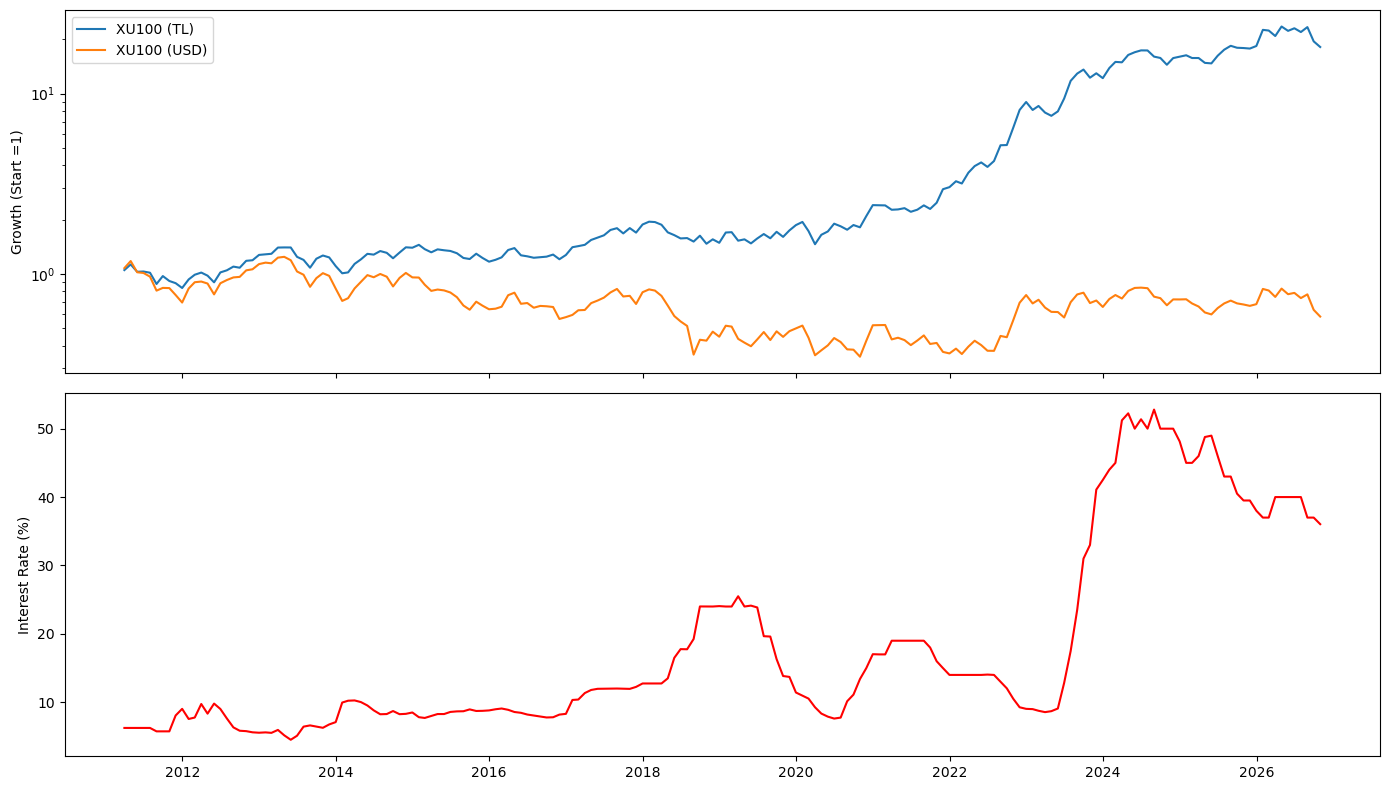

In [13]:
fig, (ax1,ax2) = plt.subplots(2,1,figsize=(14,8),sharex=True)

ax1.plot(df.index,np.exp(df["ret_tl"].cumsum()),label="XU100 (TL)")
ax1.plot(df.index,np.exp(df["ret_usd"].cumsum()),label="XU100 (USD)")
ax1.set_yscale("log")
ax1.set_ylabel("Growth (Start =1)")
ax1.legend()

ax2.plot(df.index,df["interest"],color="red")
ax2.set_ylabel("Interest Rate (%)")

plt.tight_layout()
plt.show()

Interpretation:

XU100 grew roughly twentyfold in TRY terms but ended below its starting level in the USD terms, this is indicating that most of the nominal gain reflects currency depreciation. Visually, the 2021–2023 ratecut period coincides with the fastest TRY based rally while USD based returns stayed flat or slightly negative, and the 2023 tightening coincides with a USD based recovery. This suggests the effect of rate changes may differ in sign between TRY and USD terms, which we test in the regressions. These patterns rest on a few major episodes and ignore inflation, so they are descriptive, not causal.

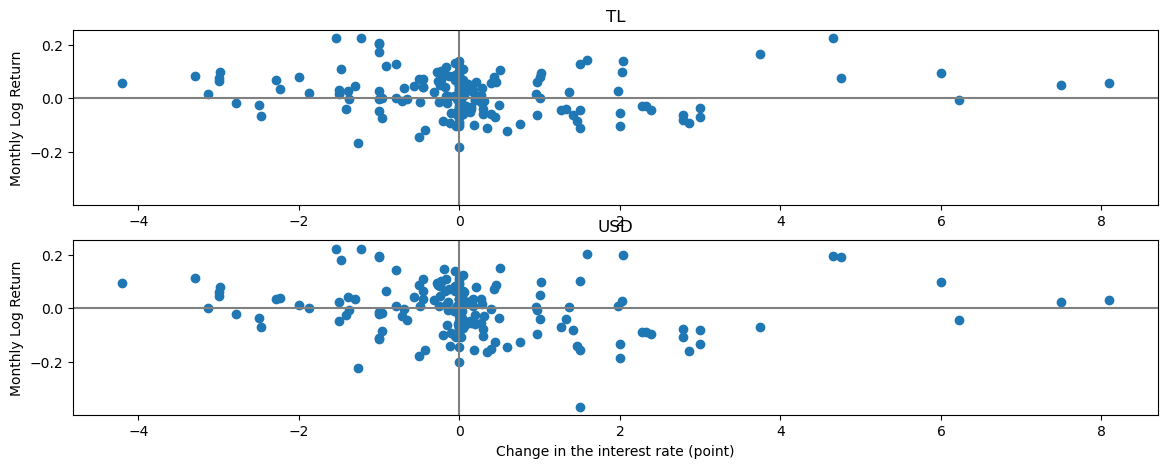

In [14]:
fig, (ax1,ax2) = plt.subplots(2,1,figsize=(14,5),sharey=True)

ax1.scatter(df["ret_r"],df["ret_tl"])
ax1.set_title("TL")
ax2.scatter(df["ret_r"],df["ret_usd"])
ax2.set_title("USD")

for ax in (ax1,ax2):
    ax2.set_xlabel("Change in the interest rate (point)")
    ax.axhline(0,color="gray")
    ax.axvline(0,color="gray")
ax1.set_ylabel("Monthly Log Return")
ax2.set_ylabel("Monthly Log Return")
plt.show()

Interpretation:

The scatter plots show no clear linear relationship between monthly rate changes and index returns; most observations form a cloud around zero. Moderate hikes which around +1 to+3 points, mostly coincide with negative returns, while the few large hikes around above +4 points, likely September 2018 and 2023, coincide with positive returns in both TRY and USD terms, suggesting a nonlinear relationship which is markets appear to reward credible, decisive tightening policy. The negative returns around moderate hikes may reflect reverse causality, as rate increases often respond to market stress within the same month. A handful of large rate changes likely drive the regression slope, so results will be checked without them at our further analysis.

<Axes: >

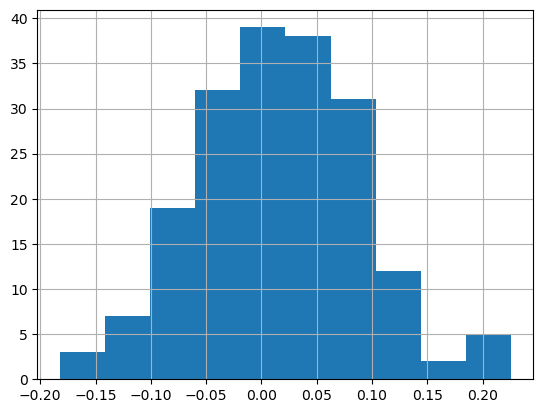

In [15]:
df["ret_tl"].hist()


<Axes: >

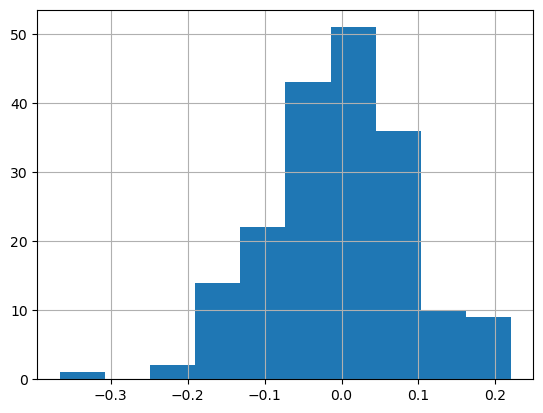

In [16]:
df["ret_usd"].hist()


<Axes: >

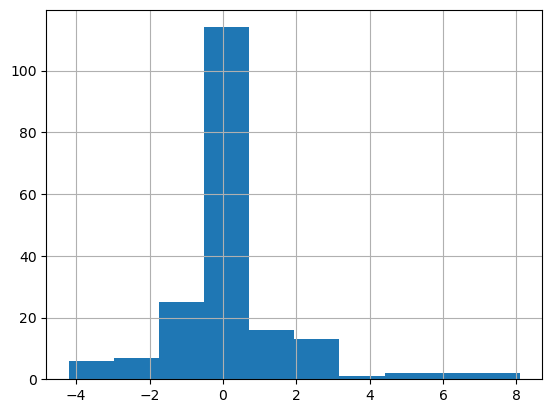

In [17]:
df["ret_r"].hist()

Interpretation of Histograms:

Monthly TRY returns are roughly symmetric and close to normal, centered at slightly above zero values, reflecting the nominal rise of the index. USD returns are centered near zero with a longer left tail, including an extreme loss in August 2018, as they combine equity and currency risk, indicates that the risk distribution has an asymmetry for foreign investors. Rate changes are concentrated at zero in most months and are right skewed: hikes reach up to 8 points while cuts rarely exceed 4, this reflecting  sharp crisis driven tightening and gradual easing. As a result, most of the information comes from a limited number of months with large rate decisions, and the few large hikes have strong influence on the regression slope.

In [18]:
df[["ret_tl","ret_usd","ret_r"]].corr()

,ret_tl,ret_usd,ret_r
ret_tl,1.000000,0.860202,-0.048077
ret_usd,0.860202,1.000000,-0.113961
ret_r,-0.048077,-0.113961,1.000000


In [19]:
df["ret_rlag1"] = df["ret_r"].shift(1)
df[["ret_tl", "ret_usd", "ret_rlag1"]].corr()

,ret_tl,ret_usd,ret_rlag1
ret_tl,1.000000,0.860202,0.029424
ret_usd,0.860202,1.000000,0.081989
ret_rlag1,0.029424,0.081989,1.000000


Interpretations of Correlation tables:

TRY and USD returns are highly correlated (0.86), so most monthly variation is shared and the difference comes from the exchange rate depreciation. Contemporaneous correlations with rate changes are weak and negative (−0.05 for TRY, −0.11 for USD), stronger in USD terms, consistent with hikes occurring in months of currency stress. With a one month lag, the sign turns positive (0.03 and 0.08), hinting at a recovery after hikes. However, with about 185 observations, a correlation must exceed roughly 0.15 in absolute value to be significant at the 5% level, so none of these relationships is statistically significant.

In [20]:
lm_tl = smf.ols("ret_tl~ret_r",data=df).fit()
lm_usd = smf.ols("ret_usd ~ ret_r", data=df).fit()


In [21]:
print(lm_tl.summary())

                            OLS Regression Results                            
Dep. Variable:                 ret_tl   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                 -0.003
Method:                 Least Squares   F-statistic:                    0.4309
Date:                Sun, 25 Oct 2026   Prob (F-statistic):              0.512
Time:                        19:56:56   Log-Likelihood:                 220.71
No. Observations:                 188   AIC:                            -437.4
Df Residuals:                     186   BIC:                            -431.0
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0158      0.006      2.861      0.0

In [22]:
print(lm_usd.summary())

                            OLS Regression Results                            
Dep. Variable:                ret_usd   R-squared:                       0.013
Model:                            OLS   Adj. R-squared:                  0.008
Method:                 Least Squares   F-statistic:                     2.447
Date:                Sun, 25 Oct 2026   Prob (F-statistic):              0.119
Time:                        19:56:56   Log-Likelihood:                 181.22
No. Observations:                 188   AIC:                            -358.4
Df Residuals:                     186   BIC:                            -352.0
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0019      0.007     -0.273      0.7

Interpretation:

In the contemporaneous models, a one point rate increase is associated with a 0.22% lower monthly return in TRY terms and 0.65% in USD terms. Neither coefficient is statistically significant (p = 0.51 and 0.12), and rate changes explain almost none of the variation in returns (R² = 0.002 and 0.013). Both coefficients are negative, so the hypothesis that rate changes affect TRY and USD returns in opposite directions is not supported in same month data; the larger USD coefficient likely reflects the currency channel, as hike months tend to coincide with lira weakness. The intercepts are more informative: the average monthly return is a significant 1.6% in TRY terms but indistinguishable from zero in USD terms, implying that the index’s nominal gains were roughly offset by currency depreciation. Residuals do not reject normality, but their variance changes over time, so p-values should be interpreted with caution.

In [23]:
lm_tl_lag = smf.ols("ret_tl~ret_rlag1",data=df).fit()
lm_usd_lag = smf.ols("ret_usd~ret_rlag1",data=df).fit()

In [24]:
print(lm_tl_lag.summary())

                            OLS Regression Results                            
Dep. Variable:                 ret_tl   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                 -0.005
Method:                 Least Squares   F-statistic:                    0.1603
Date:                Sun, 25 Oct 2026   Prob (F-statistic):              0.689
Time:                        19:56:56   Log-Likelihood:                 219.01
No. Observations:                 187   AIC:                            -434.0
Df Residuals:                     185   BIC:                            -427.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0150      0.006      2.707      0.0

In [25]:
print(lm_usd_lag.summary())

                            OLS Regression Results                            
Dep. Variable:                ret_usd   R-squared:                       0.007
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     1.252
Date:                Sun, 25 Oct 2026   Prob (F-statistic):              0.265
Time:                        19:56:56   Log-Likelihood:                 179.52
No. Observations:                 187   AIC:                            -355.0
Df Residuals:                     185   BIC:                            -348.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0041      0.007     -0.596      0.5

Interpretation:

With a one month lag, the rate change coefficients turn positive (0.0014 for TRY, 0.0047 for USD), suggesting a possible pattern of declines in hike months followed by mild recoveries. However, neither coefficient is significant (p = 0.69 and 0.27) and R² is close to zero, so this month’s rate change does not predict next month’s returns. This is consistent with markets incorporating publicly announced rate decisions quickly.

In [26]:
models = {"TL Contemporaneous": lm_tl, "USD Contemporaneous": lm_usd,
          "TL lagged": lm_tl_lag, "USD lagged": lm_usd_lag}

pd.DataFrame({name: [m.params.iloc[1], m.pvalues.iloc[1], m.rsquared]
              for name, m in models.items()},
             index=["Coefficient", "p", "R²"]).T

,Coefficient,p,R²
TL Contemporaneous,-0.002224,0.512353,0.002311
USD Contemporaneous,-0.006538,0.119421,0.012987
TL lagged,0.001362,0.689334,0.000866
USD lagged,0.004701,0.264619,0.006722


Interpretation:

Across all four specifications, rate changes have no statistically significant relationship with BIST100 returns, and they explain at most 1.3% of the monthly variation. The coefficients are negative in the same month and positive with a one-month lag, consistent with declines in hike months followed by mild recoveries, but this pattern is not significant. The sign is the same in TRY and USD terms, while USD coefficients are roughly three times larger, suggesting that any effect of rate changes runs mainly through the exchange rate.

# SUBPERIOD ANALYSIS

In [27]:
df["ret_r"] = pd.to_numeric(df["ret_r"].astype(str).str.replace(",", "."), errors="coerce")

periods = {
    "2011–2021/08": ("2011-01-31", "2021-08-31"),
    "2021/09–2023/05": ("2021-09-30", "2023-05-31"),
    "2023/06–": ("2023-06-30", None),
}

rows = []
for name, (start, end) in periods.items():
    sub = df.loc[start:end]
    for y in ["ret_tl", "ret_usd"]:
        m = smf.ols(f"{y} ~ ret_r", data=sub).fit()
        rows.append([name, y, len(sub), m.params["ret_r"], m.pvalues["ret_r"], m.rsquared])

pd.DataFrame(rows, columns=["Period", "Return", "n", "Coefficient", "p", "R²"])

,Period,Return,n,Coefficient,p,R²
0,2011–2021/08,ret_tl,126,-0.007925,0.142979,0.017223
1,2011–2021/08,ret_usd,126,-0.017203,0.027239,0.038709
2,2021/09–2023/05,ret_tl,21,-0.067998,0.039095,0.205380
3,2021/09–2023/05,ret_usd,21,-0.052994,0.148088,0.106851
4,2023/06–,ret_tl,41,0.003267,0.494111,0.012070
5,2023/06–,ret_usd,41,-0.000232,0.960466,0.000064


Interpretation:

Splitting the sample reveals that the relationship between rate changes and returns is not stable across policy regimes, which explains why the full-sample estimates are insignificant. In 2011–2021, rate changes are negatively related to returns, significantly so in USD terms (−1.7% per point, p = 0.03), consistent with hikes being reactions to currency pressure. 

During the 2021–2023 easing period, the coefficients are about ten times larger: each one point cut is associated with a 6.8% higher monthly TRY return (p = 0.04, R² = 0.21), matching the TRY rally in the level chart, while the USD effect is not significant.
A possible interpretation is that rate cuts made while inflation was rising pushed real interest rates deeply negative, leading investors to use equities as a hedge against inflation and currency depreciation. This would explain why the effect appears in TRY terms but not in USD terms. However, since inflation is not included in our data, this explanation remains a hypothesis.
This finding should also be interpreted with caution because the period contains only 21 observations, and rate changes occurred in fewer than half of these months. One or two months could change the outcome substantially.

After June 2023, the relationship disappears.

Finally, we ran six tests and two of them were significant. Even if no true relationship existed, the probability of obtaining at least one false positive in six tests would be about 26%. Since the results are consistent with the pattern observed in the level chart, it is less likely that they are purely due to chance, but this possibility cannot be ruled out.

# ASSUMPTIONS TESTING

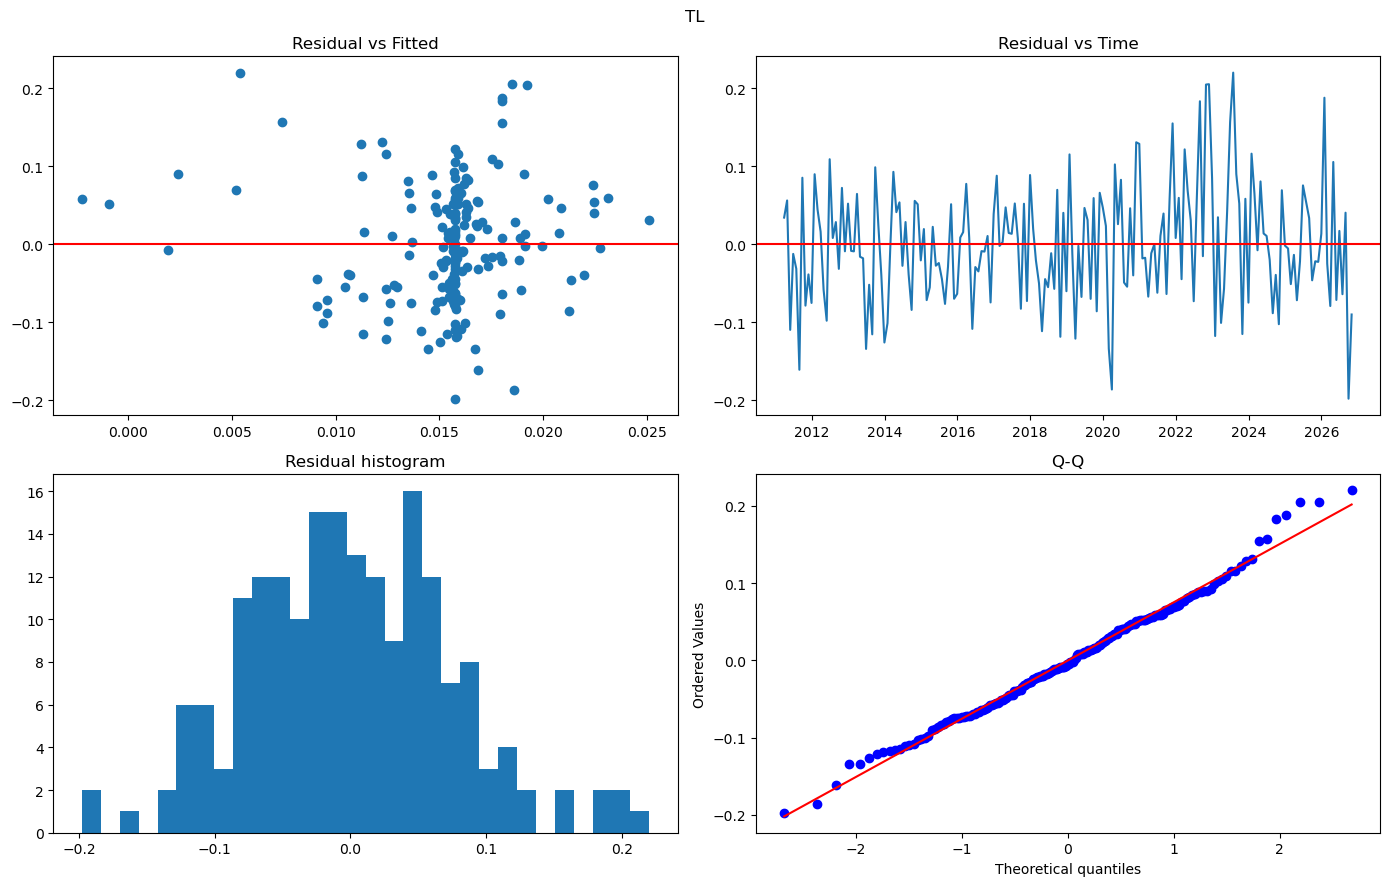

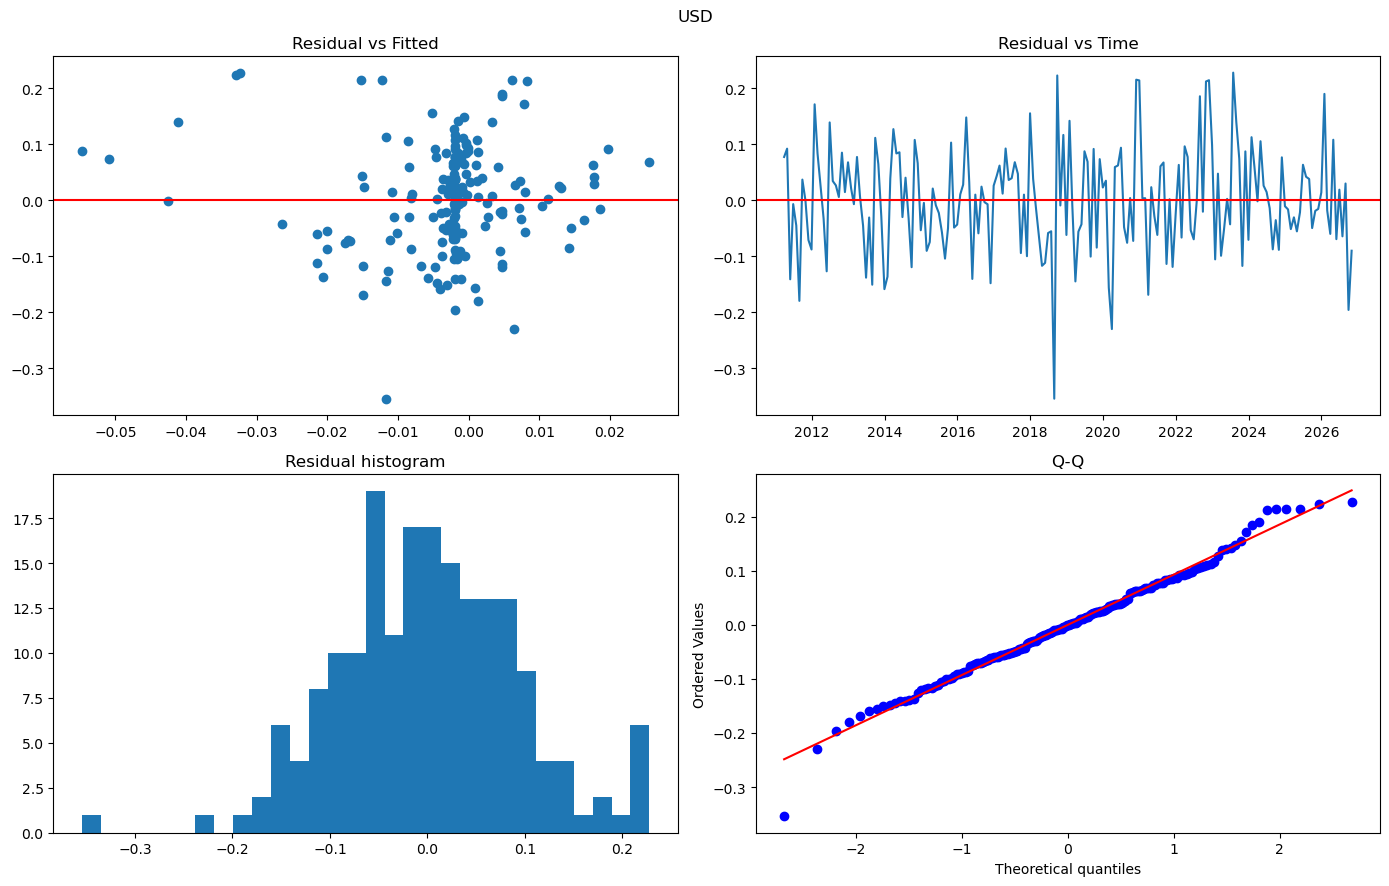

In [31]:
import scipy.stats as stats

def check(model,title):
    resid = model.resid
    fitted = model.fittedvalues
    fig,ax = plt.subplots(2,2,figsize=(14,9))

 # 1. Linearity
    ax[0, 0].scatter(fitted, resid)
    ax[0, 0].axhline(0, color="red")
    ax[0, 0].set_title("Residual vs Fitted")

    # 2. Independence
    ax[0, 1].plot(resid.index, resid)
    ax[0, 1].axhline(0, color="red")
    ax[0, 1].set_title("Residual vs Time")

    # 3. Normality
    ax[1, 0].hist(resid, bins=30)
    ax[1, 0].set_title("Residual histogram")
    stats.probplot(resid, dist="norm", plot=ax[1, 1])
    ax[1, 1].set_title("Q-Q")

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
check(lm_tl,"TL")
check(lm_usd,"USD")

Interpretation:

Linearity: Most fitted values cluster around the intercept (about 0.015 for TRY and 0 for USD), reflecting the many months with little or no rate change. The few months with large hikes, which produce the lowest fitted values, have mostly positive residuals: the model systematically underestimates returns in those months. This is consistent with the nonlinear pattern in the scatter plots, where large hikes coincided with positive returns. (Violated)

Independence: The Durbin–Watson statistics (1.83 for TRY, 1.89 for USD) are close to 2, indicating no meaningful autocorrelation in the residuals. (Satisfied)

Equal variance: Residual volatility is not constant over time; it increases markedly around 2018 and during 2021–2024. This violates the equal-variance assumption, so the standard errors and p-values should be treated as approximate. (Violated)

Normality: The Q–Q plots are close to the reference line and the Jarque–Bera tests do not reject normality (p = 0.27 and 0.14), apart from a few large residuals in the tails, such as the August 2018 currency crisis in USD terms. Monthly returns are closer to normal than daily returns because each is the sum of roughly 21 daily returns. (Satisfied)

Two of the four assumptions (independence and normality) are reasonably satisfied, while linearity and equal variance are violated. The coefficient estimates remain informative, but their standard errors and p-values should be treated as approximate, and a single linear relationship does not fully capture the effect of large rate hikes. Since R² is close to zero, the model is not useful for prediction either.

In [29]:
smf.ols("ret_tl ~ ret_r", data=df[df["ret_r"].abs() < 5]).fit().summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 ret_tl   R-squared:                       0.013
Model:                            OLS   Adj. R-squared:                  0.008
Method:                 Least Squares   F-statistic:                     2.408
Date:                Sun, 25 Oct 2026   Prob (F-statistic):              0.122
Time:                        19:56:58   Log-Likelihood:                 215.86
No. Observations:                 184   AIC:                            -427.7
Df Residuals:                     182   BIC:                            -421.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0148      0.006      2.661      0.008       0.004       0.026
ret_r         -0.0067      0.004     -1.552      0.122      -0.015       0.002
==============================================================================
Omnibus:                        5.571   Durbin-Watson:                   1.857
Prob(Omnibus):                  0.062   Jarque-Bera (JB):                5.215
Skew:                           0.352   Prob(JB):                       0.0737
Kurtosis:                       3.431   Cond. No.                         1.28
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [30]:
smf.ols("ret_usd ~ ret_r", data=df[df["ret_r"].abs() < 5]).fit().summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                ret_usd   R-squared:                       0.034
Model:                            OLS   Adj. R-squared:                  0.029
Method:                 Least Squares   F-statistic:                     6.370
Date:                Sun, 25 Oct 2026   Prob (F-statistic):             0.0125
Time:                        19:56:58   Log-Likelihood:                 178.15
No. Observations:                 184   AIC:                            -352.3
Df Residuals:                     182   BIC:                            -345.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0034      0.007     -0.499      0.618      -0.017       0.010
ret_r         -0.0134      0.005     -2.524      0.012      -0.024      -0.003
==============================================================================
Omnibus:                        4.890   Durbin-Watson:                   1.925
Prob(Omnibus):                  0.087   Jarque-Bera (JB):                6.649
Skew:                           0.070   Prob(JB):                       0.0360
Kurtosis:                       3.921   Cond. No.                         1.28
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Interpretation:

Robustness check (excluding |rate change| ≥ 5 points, n = 184):

* Excluding the four months with the largest rate hikes substantially strengthens the negative relationship in both models. In TRY terms, the coefficient triples from −0.0022 to −0.0067 (p = 0.12), and in USD terms it doubles from −0.0065 to −0.0134, becoming statistically significant (p = 0.01, 95% CI: −0.024 to −0.003, R² = 0.034). For ordinary rate changes, a one-point hike is thus associated with a 1.3% lower monthly return in USD terms, while a handful of large, decisive hikes coincided with positive returns and masked this relationship in the full sample. The effect of rate changes appears to depend on their size, and it is stronger in USD terms, consistent with the exchange-rate channel identified earlier.

These results should be interpreted with caution. The 5 point threshold was chosen after inspecting the scatter plots, so this is an exploratory finding rather than a confirmatory test, and the growing number of tests increases the chance of a false positive. In addition, the Jarque–Bera test rejects normality for the USD model (p = 0.04 instead of expected 0.05<p), and the equal-variance violation still applies, so the p-values are approximate. Even so, R² remains below 4%: rate changes explain only a small part of monthly index returns.

## Conclusion

This project examined whether changes in the Turkish policy-related interest rate (CBRT weighted average cost of funding) explain BIST100 returns, and whether the relationship differs between TRY and USD terms. We used roughly 15 years of monthly data (about 188 observations) and estimated simple linear regressions of index returns on same-month and one-month-lagged rate changes.

### Main findings

1. **Nominal gains largely reflect currency depreciation.** The index rose about twentyfold in TRY terms but ended below its starting level in USD terms. The average monthly return is a significant 1.6% in TRY terms and indistinguishable from zero in USD terms; the difference roughly equals the average monthly depreciation of the lira.

2. **No significant relationship in the full sample.** Same-month rate changes are negatively but insignificantly related to returns (TRY: p = 0.51, USD: p = 0.12), and they explain at most 1.3% of monthly return variation. The sign is the same in TRY and USD terms, so the hypothesis of opposite effects is not supported; the larger USD coefficient points to the exchange-rate channel.

3. **No predictive power.** Lagged rate changes do not predict next month's returns (p = 0.69 and 0.27, R² below 1%), consistent with markets quickly pricing in publicly announced decisions.

4. **The relationship depends on the policy regime.** In 2011–2021, hikes were associated with lower USD returns (p = 0.03). During the 2021–2023 easing period, each one-point cut was associated with a 6.8% higher monthly TRY return (p = 0.04) but no significant USD effect, consistent with investors using equities as a hedge against inflation and depreciation. After mid-2023, the relationship disappears.

5. **The effect depends on the size of the change.** Excluding the four largest hikes doubles to triples the negative coefficients, making the USD effect significant (−1.3% per point, p = 0.01). Large, decisive hikes coincided with positive returns, while ordinary hikes coincided with negative ones. A single linear model cannot capture this pattern.

### Limitations

- **Small and regime-dependent sample:** Most months have little or no rate change, so the results rely on a limited number of decisions. The 2021–2023 subsample contains only 21 observations.
- **Reverse causality:** Rate hikes often respond to market stress within the same month, so the contemporaneous estimates describe co-movement rather than causal effects.
- **Omitted inflation:** The analysis uses nominal rates. The same nominal rate implies very different real policy stances across periods, and inflation is not included in the model.
- **Assumption violations:** Residual variance changes over time and the relationship is not linear, so p-values should be treated as approximate.
- **Multiple and exploratory tests:** Several specifications were tested, and the robustness threshold was chosen after inspecting the data. The significant subsample and robustness results should therefore be viewed as exploratory.
- **Incomplete final month:** October 2026 data covers only part of the month.

### Overall

Rate changes alone explain very little of BIST100's monthly returns. Their effect appears to depend on the policy regime and on the size and credibility of the decision rather than following a single stable linear relationship. In TRY terms, the index's long-run rise mainly reflects the loss in the lira's value rather than real value creation.

### Further work

Natural extensions include using real interest rates (adjusting for inflation), analyzing returns around the exact dates of rate decisions instead of monthly data, and allowing the effect to differ between cuts, moderate hikes and large hikes.

Analysis made by Metehan Çiftçi